# 02 · Рекомендации по популярности

Начинаю с простого решения: рекомендовать объекты, которые посмотрело больше всего пользователей. Оно задаёт ориентир для остальных моделей и даёт выдачу пользователям без истории.

Популярность считаю по положительным просмотрам до 9 августа. Из рекомендаций исключаю всё, что пользователь уже смотрел, даже если просмотр был короче выбранного порога. Оцениваю следующую неделю; финальный Test беру из общего запуска экспериментов.

## Данные и разбиение

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA_DIR = Path(os.environ.get("KION_DATA_DIR", ROOT / "data"))
REPORTS = ROOT / "reports" / "full"
K = 10
blas_limit = threadpool_limits(limits=1, user_api="blas")
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

In [2]:
from kion_recsys.models import PopularRecommender

In [3]:
from kion_recsys.data import TrainingData, load_interactions, split_interactions
from kion_recsys.metrics import build_targets, ranking_metrics

interactions = load_interactions(DATA_DIR)
raw_train, raw_validation, raw_test = split_interactions(interactions, None)
train, validation, test = split_interactions(interactions)
training_data = TrainingData.from_frame(train, raw_train)
validation_targets = build_targets(raw_train, validation)
selected = json.loads((REPORTS / "selected_params.json").read_text())
metrics = pd.read_csv(REPORTS / "metrics.csv")
print(
    f"Train: {len(train):,} positive pairs; "
    f"validation users: {len(validation_targets):,}"
)

Train: 2,686,055 positive pairs; validation users: 103,258


## Популярность объектов

Популярность — число уникальных пользователей, взаимодействовавших с объектом в Train. Значения из Validation и Test при построении рейтинга не используются.

In [4]:
popularity = train.groupby("item_id")["user_id"].nunique().sort_values(ascending=False)

items = pd.read_csv(DATA_DIR / "items.csv")
top_items = (
    popularity.head(10)
    .rename("viewers")
    .rename_axis("item_id")
    .reset_index()
    .merge(items[["item_id", "title"]], on="item_id", how="left")
)
display(top_items[["item_id", "title", "viewers"]])

,item_id,title,viewers
0,15297,Клиника счастья,126046
1,10440,Хрустальный,119077
2,13865,Девятаев,82489
3,9728,Гнев человеческий,73261
4,3734,Прабабушка легкого поведения,52917
5,4151,Секреты семейной жизни,46686
6,142,Маша,29110
7,6809,Дуров,23364
8,8636,Белый снег,22977
9,11237,День города,18270


## Валидация

Для каждого пользователя из Validation формируется Top-10 без фильмов из его истории Train.

- **MAP@10** — средняя точность с учётом позиций релевантных объектов;
- **Recall@10** — доля найденных будущих взаимодействий;
- **HitRate@10** — доля пользователей хотя бы с одним попаданием;
- **Coverage** — доля обучающего каталога, появившаяся в рекомендациях.
- **NDCG@10** — нормированный DCG с бинарной релевантностью и логарифмической скидкой.

In [5]:
popular = PopularRecommender().fit(training_data)
validation_recs = popular.recommend(validation_targets, k=K)
validation_metrics = ranking_metrics(
    validation_recs, validation_targets, popular.n_items, k=K
)
display(pd.Series(validation_metrics, name="Validation").to_frame())

,Validation
MAP@10,0.135087
Recall@10,0.255610
NDCG@10,0.175099
HitRate@10,0.331054
Coverage,0.002598
Users,103258.000000


## Тест

Перед оценкой на Test модель переобучается на Train + Validation. Тестовый период не используется ни для подсчёта популярности, ни для выбора параметров.

,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage,Users
split,,,,,,
validation,0.1351,0.2556,0.1751,0.3311,0.0026,103258
test,0.1215,0.2366,0.1598,0.3127,0.0027,106819


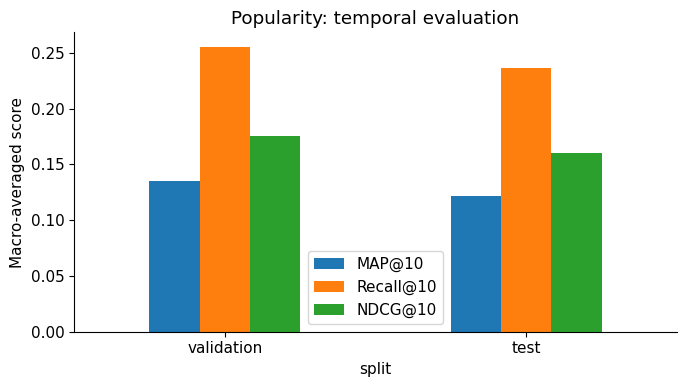

In [6]:
results = metrics.query("model == 'Popularity'").set_index("split")
display(results.drop(columns=["model", "seconds"]).round(4))
fig, ax = plt.subplots(figsize=(7, 4))
results[["MAP@10", "Recall@10", "NDCG@10"]].plot.bar(ax=ax, rot=0)
ax.set(title="Popularity: temporal evaluation", ylabel="Macro-averaged score")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

## Выводы

На Test получился MAP@10 **0.1215** и Recall@10 **0.2366**. Хотя модель не учитывает вкусы пользователя, хотя бы одно попадание есть у 31.3% пользователей.

При этом в выдачу попадает только 0.27% каталога. Дальше попробую ItemKNN: он должен подбирать объекты по конкретной истории, а не только из общего списка хитов. Проверю, как изменятся и качество, и покрытие.